# Data Mining Kredit: Preprocessing dan Decision Tree

Notebook ini mengerjakan 3 tahap secara berurutan, sama seperti alur di Orange:

| Tahap | Isi | Padanan widget Orange |
|---|---|---|
| 1 | Data Cleansing dan Integration | File, Merge Data, Unique, Impute, Outliers |
| 2 | Transformation dan Reduction | Normalize, Discretize, Continuize, Rank, PCA, Data Sampler |
| 3 | Klasifikasi Decision Tree | Tree, Tree Viewer, Test and Score, Confusion Matrix |

**Persiapan:** simpan file notebook ini dan dua file CSV (`kredit_1_demografi.csv`, `kredit_2_keuangan.csv`) dalam **satu folder yang sama**. Jalankan sel dari atas ke bawah dengan `Shift + Enter`.

Kalau library belum ada: `pip install pandas scikit-learn matplotlib notebook`

## 0. Persiapan: memanggil library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_columns", 30)
print("Library siap dipakai")

Library siap dipakai


# TAHAP 1: Data Cleansing dan Integration

## 1.1 Membaca kedua file
Data kita terpecah menjadi dua tabel: **demografi** dan **keuangan**. Keduanya punya kolom penghubung `ID_Nasabah`.
(Di Orange: widget **File**, dua kali.)

In [2]:
demo = pd.read_csv("kredit_1_demografi.csv")
fin  = pd.read_csv("kredit_2_keuangan.csv")

print("Demografi:", demo.shape)
print("Keuangan :", fin.shape)
display(demo.head(3))
display(fin.head(3))

Demografi: (1225, 8)
Keuangan : (1215, 9)


,ID_Nasabah,Usia,Jenis_Kelamin,Pendidikan,Status_Pernikahan,Pekerjaan,Jumlah_Tanggungan,Kota
0,N0647,41.0,Perempuan,SMA,Menikah,PNS,0,Medan
1,N0147,22.0,Laki-laki,SMA,Belum Menikah,Profesional,1,Bandung
2,N0613,56.0,L,S1,Belum Menikah,Wiraswasta,1,Denpasar


,ID_Nasabah,Pendapatan_Bulanan_Juta,Jumlah_Pinjaman_Juta,Tenor_Bulan,Skor_Kredit,Riwayat_Kredit,Jumlah_Pinjaman_Aktif,Lama_Bekerja_Tahun,Status_Persetujuan
0,N0502,10.5,50.0,48,585.0,Cukup,0,23.0,Disetujui
1,N0167,8.6,73.0,60,728.0,Baik,0,11.0,Disetujui
2,N0359,8.6,624.0,48,738.0,Baik,1,0.0,Ditolak


## 1.2 Menghapus data duplikat
Duplikat dibuang **sebelum** digabung. Kalau tidak, satu nasabah yang tercatat dua kali akan menjadi 2 x 2 = 4 baris setelah digabung.
(Di Orange: widget **Unique**.)

In [3]:
print("Duplikat demografi:", demo.duplicated().sum())
print("Duplikat keuangan :", fin.duplicated().sum())

demo = demo.drop_duplicates()
fin  = fin.drop_duplicates()

print("\nSetelah dibersihkan:", demo.shape, fin.shape)
print("ID unik? demografi:", demo["ID_Nasabah"].is_unique, "| keuangan:", fin["ID_Nasabah"].is_unique)

Duplikat demografi: 25
Duplikat keuangan : 15

Setelah dibersihkan: (1200, 8) (1200, 9)
ID unik? demografi: True | keuangan: True


## 1.3 Integrasi: menggabungkan dua tabel
Kita gabungkan berdasarkan `ID_Nasabah` dengan **inner join** (hanya nasabah yang ada di kedua tabel).
(Di Orange: widget **Merge Data**.)

In [4]:
df = demo.merge(fin, on="ID_Nasabah", how="inner")

print("Hasil gabungan:", df.shape)
assert len(df) == 1200, "Jumlah baris seharusnya 1200"
df.head()

Hasil gabungan: (1200, 16)


,ID_Nasabah,Usia,Jenis_Kelamin,Pendidikan,Status_Pernikahan,Pekerjaan,Jumlah_Tanggungan,Kota,Pendapatan_Bulanan_Juta,Jumlah_Pinjaman_Juta,Tenor_Bulan,Skor_Kredit,Riwayat_Kredit,Jumlah_Pinjaman_Aktif,Lama_Bekerja_Tahun,Status_Persetujuan
0,N0647,41.0,Perempuan,SMA,Menikah,PNS,0,Medan,10.6,28.0,36,537.0,Buruk,0,19.0,Ditolak
1,N0147,22.0,Laki-laki,SMA,Belum Menikah,Profesional,1,Bandung,8.9,464.0,24,469.0,Buruk,3,0.0,Ditolak
2,N0613,56.0,L,S1,Belum Menikah,Wiraswasta,1,Denpasar,15.6,161.0,12,622.0,Cukup,2,17.0,Ditolak
3,N0356,65.0,Perempuan,S2,Menikah,NaN,0,Jakarta,18.2,309.0,36,484.0,Buruk,3,5.0,Ditolak
4,N0743,49.0,Laki-laki,D3,Belum Menikah,Wiraswasta,2,Jakarta,6.3,34.0,48,653.0,Cukup,3,16.0,Ditolak


## 1.4 Memeriksa missing value
Kolom mana saja yang punya data kosong?

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0]
print(pd.DataFrame({"jumlah_kosong": missing, "persen": (missing / len(df) * 100).round(1)}))

                         jumlah_kosong  persen
Usia                                36     3.0
Pendidikan                          24     2.0
Pekerjaan                           24     2.0
Pendapatan_Bulanan_Juta             48     4.0
Skor_Kredit                         36     3.0
Lama_Bekerja_Tahun                  36     3.0


## 1.5 Menyeragamkan label yang tidak konsisten
Kolom `Jenis_Kelamin` berisi penulisan campuran (`L`, `P`, `laki-laki`, `LAKI-LAKI`, `perempuan ` dengan spasi). Komputer menganggap semuanya kategori berbeda.
(Di Orange: widget **Edit Domain**, menu *Merge values*.)

In [6]:
print("SEBELUM:")
print(df["Jenis_Kelamin"].value_counts())

peta = {"laki-laki": "Laki-laki", "l": "Laki-laki", "perempuan": "Perempuan", "p": "Perempuan"}
df["Jenis_Kelamin"] = df["Jenis_Kelamin"].str.strip().str.lower().map(peta)

print("\nSESUDAH:")
print(df["Jenis_Kelamin"].value_counts())
assert df["Jenis_Kelamin"].isna().sum() == 0

SEBELUM:
Jenis_Kelamin
Laki-laki     634
Perempuan     506
L              16
perempuan      14
laki-laki      12
P              10
LAKI-LAKI       8
Name: count, dtype: int64

SESUDAH:
Jenis_Kelamin
Laki-laki    670
Perempuan    530
Name: count, dtype: int64


## 1.6 Mendeteksi dan menangani outlier
Outlier adalah nilai yang tidak masuk akal. Kita lihat dulu lewat boxplot, titik di luar kotak adalah kandidat outlier.
(Di Orange: widget **Box Plot** atau **Outliers**.)

/tmp/ipykernel_356/3711744698.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0].boxplot(df["Usia"].dropna(), vert=False)
/tmp/ipykernel_356/3711744698.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(df["Pendapatan_Bulanan_Juta"].dropna(), vert=False)


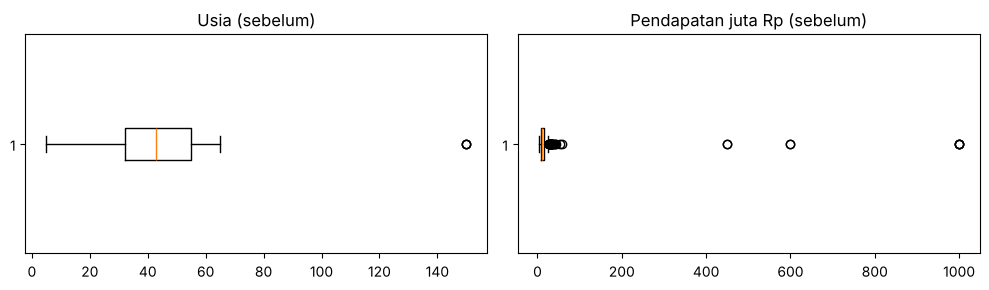

Usia min/max       : 5.0 / 150.0
Pendapatan min/max : 3.0 / 999.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].boxplot(df["Usia"].dropna(), vert=False)
ax[0].set_title("Usia (sebelum)")
ax[1].boxplot(df["Pendapatan_Bulanan_Juta"].dropna(), vert=False)
ax[1].set_title("Pendapatan juta Rp (sebelum)")
plt.tight_layout()
plt.show()

print("Usia min/max       :", df["Usia"].min(), "/", df["Usia"].max())
print("Pendapatan min/max :", df["Pendapatan_Bulanan_Juta"].min(), "/", df["Pendapatan_Bulanan_Juta"].max())

Aturan yang kita pakai (aturan bisnis yang masuk akal):
- Usia nasabah kredit harus **17 sampai 70 tahun**.
- Pendapatan bulanan di atas **100 juta** dianggap salah input.

Nilai yang melanggar aturan diubah menjadi kosong (`NaN`), lalu diisi bersama missing value lain di langkah berikutnya.

In [8]:
usia_salah = (df["Usia"] < 17) | (df["Usia"] > 70)
gaji_salah = df["Pendapatan_Bulanan_Juta"] > 100

print("Outlier usia      :", usia_salah.sum())
print("Outlier pendapatan:", gaji_salah.sum())

df.loc[usia_salah, "Usia"] = np.nan
df.loc[gaji_salah, "Pendapatan_Bulanan_Juta"] = np.nan

Outlier usia      : 5
Outlier pendapatan: 8


## 1.7 Mengisi missing value (imputasi)
- Kolom **angka** diisi dengan **median** (tahan terhadap nilai ekstrem).
- Kolom **kategori** diisi dengan **modus** (nilai yang paling sering muncul).

(Di Orange: widget **Impute**.)

In [9]:
kolom_num = df.select_dtypes(include="number").columns
kolom_kat = df.select_dtypes(exclude="number").columns.drop("ID_Nasabah")

for k in kolom_num:
    df[k] = df[k].fillna(df[k].median())
for k in kolom_kat:
    df[k] = df[k].fillna(df[k].mode()[0])

# usia dan lama bekerja lebih natural sebagai bilangan bulat
df["Usia"] = df["Usia"].round().astype(int)
df["Lama_Bekerja_Tahun"] = df["Lama_Bekerja_Tahun"].round().astype(int)

print("Sisa missing value:", int(df.isna().sum().sum()))
print("Ukuran data bersih:", df.shape)
df.describe().round(1)

Sisa missing value: 0
Ukuran data bersih: (1200, 16)


,Usia,Jumlah_Tanggungan,Pendapatan_Bulanan_Juta,Jumlah_Pinjaman_Juta,Tenor_Bulan,Skor_Kredit,Jumlah_Pinjaman_Aktif,Lama_Bekerja_Tahun
count,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,43.1,1.6,11.8,122.7,37.9,649.9,1.2,10.4
std,12.8,1.3,6.0,114.6,14.7,95.2,1.1,7.9
min,21.0,0.0,3.0,10.0,12.0,385.0,0.0,0.0
25%,32.0,1.0,7.6,50.0,24.0,583.0,0.0,4.0
50%,43.0,1.0,10.6,87.0,36.0,661.0,1.0,9.0
75%,54.0,2.0,14.4,151.0,48.0,720.2,2.0,17.0
max,65.0,5.0,57.1,800.0,60.0,850.0,5.0,29.0


## 1.8 Menyimpan data bersih
File ini bisa langsung dibuka di Orange (widget **File**) kalau Anda ingin membandingkan hasilnya.

In [10]:
df.to_csv("kredit_bersih.csv", index=False)
print("Tersimpan: kredit_bersih.csv")

Tersimpan: kredit_bersih.csv


# TAHAP 2: Transformation dan Reduction

## 2.1 Membuat atribut baru (feature construction)
`Rasio_Cicilan` = cicilan per bulan dibagi pendapatan per bulan. Atribut ini lebih informatif daripada pinjaman dan pendapatan yang berdiri sendiri, karena langsung menunjukkan **beban cicilan**.
(Di Orange: widget **Feature Constructor**.)

In [11]:
cicilan_bulanan = df["Jumlah_Pinjaman_Juta"] * 1.1 / df["Tenor_Bulan"]   # asumsi bunga total 10%
df["Rasio_Cicilan"] = (cicilan_bulanan / df["Pendapatan_Bulanan_Juta"]).round(3)

df[["Pendapatan_Bulanan_Juta", "Jumlah_Pinjaman_Juta", "Tenor_Bulan", "Rasio_Cicilan"]].head()

,Pendapatan_Bulanan_Juta,Jumlah_Pinjaman_Juta,Tenor_Bulan,Rasio_Cicilan
0,10.6,28.0,36,0.081
1,8.9,464.0,24,2.390
2,15.6,161.0,12,0.946
3,18.2,309.0,36,0.519
4,6.3,34.0,48,0.124


## 2.2 Normalisasi (min-max)
Mengubah semua angka ke skala **0 sampai 1** supaya atribut bersatuan besar (misal skor kredit 300-850) tidak mendominasi atribut bersatuan kecil.
(Di Orange: widget **Normalize**.)

> Catatan: Decision Tree sebenarnya **tidak butuh** normalisasi. Kita tetap mempraktikkannya karena ini bagian dari materi, tetapi untuk pohon nanti kita pakai data asli supaya aturan lebih mudah dibaca (misal "Skor_Kredit <= 600" lebih jelas daripada "Skor_Kredit <= 0.55").

In [12]:
kolom_kontinu = ["Usia", "Pendapatan_Bulanan_Juta", "Jumlah_Pinjaman_Juta",
                 "Skor_Kredit", "Lama_Bekerja_Tahun", "Rasio_Cicilan"]

df_norm = df.copy()
df_norm[kolom_kontinu] = MinMaxScaler().fit_transform(df[kolom_kontinu])

print("Setelah normalisasi (semua harus 0 sampai 1):")
df_norm[kolom_kontinu].describe().loc[["min", "max"]].round(2)

Setelah normalisasi (semua harus 0 sampai 1):


,Usia,Pendapatan_Bulanan_Juta,Jumlah_Pinjaman_Juta,Skor_Kredit,Lama_Bekerja_Tahun,Rasio_Cicilan
min,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0


## 2.3 Diskretisasi
Mengubah angka menjadi kelompok/kategori.
- `Usia` dipotong dengan batas yang kita tentukan sendiri (*equal-width* manual).
- `Pendapatan` dipotong menjadi 3 kelompok berisi jumlah data yang sama (*equal-frequency*).

(Di Orange: widget **Discretize**.)

In [13]:
df["Kelompok_Usia"] = pd.cut(df["Usia"], bins=[0, 30, 40, 50, 100],
                             labels=["<=30", "31-40", "41-50", ">50"])
df["Kelas_Pendapatan"] = pd.qcut(df["Pendapatan_Bulanan_Juta"], q=3,
                                 labels=["Rendah", "Sedang", "Tinggi"])

print(df["Kelompok_Usia"].value_counts().sort_index())
print()
print(df["Kelas_Pendapatan"].value_counts().sort_index())

Kelompok_Usia
<=30     256
31-40    238
41-50    314
>50      392
Name: count, dtype: int64

Kelas_Pendapatan
Rendah    402
Sedang    401
Tinggi    397
Name: count, dtype: int64


## 2.4 Encoding: mengubah kategori menjadi angka
Library Python membutuhkan input angka.
- Kategori **berurutan** (Pendidikan, Riwayat_Kredit) menjadi angka berurutan.
- Kategori **tidak berurutan** (Kota, Pekerjaan, dst.) menjadi kolom 0/1 (*one-hot*).
- Kelas target: `Disetujui` = 1, `Ditolak` = 0.

(Di Orange: widget **Continuize**.)

In [14]:
df_model = df.drop(columns=["ID_Nasabah", "Kelompok_Usia", "Kelas_Pendapatan"])

df_model["Pendidikan"] = df_model["Pendidikan"].map({"SMA": 1, "D3": 2, "S1": 3, "S2": 4, "S3": 5})
df_model["Riwayat_Kredit"] = df_model["Riwayat_Kredit"].map({"Buruk": 0, "Cukup": 1, "Baik": 2})

y = (df_model.pop("Status_Persetujuan") == "Disetujui").astype(int)
X = pd.get_dummies(df_model, columns=["Jenis_Kelamin", "Status_Pernikahan", "Pekerjaan", "Kota"], dtype=int)

print("Jumlah atribut sekarang:", X.shape[1])
print("Proporsi kelas: Disetujui =", round(y.mean(), 3), "| Ditolak =", round(1 - y.mean(), 3))
X.head(3)

Jumlah atribut sekarang: 30
Proporsi kelas: Disetujui = 0.58 | Ditolak = 0.42


,Usia,Pendidikan,Jumlah_Tanggungan,Pendapatan_Bulanan_Juta,Jumlah_Pinjaman_Juta,Tenor_Bulan,Skor_Kredit,Riwayat_Kredit,Jumlah_Pinjaman_Aktif,Lama_Bekerja_Tahun,Rasio_Cicilan,Jenis_Kelamin_Laki-laki,Jenis_Kelamin_Perempuan,Status_Pernikahan_Belum Menikah,Status_Pernikahan_Cerai,Status_Pernikahan_Menikah,Pekerjaan_Buruh,Pekerjaan_Karyawan Swasta,Pekerjaan_PNS,Pekerjaan_Pensiunan,Pekerjaan_Profesional,Pekerjaan_Wiraswasta,Kota_Bandung,Kota_Denpasar,Kota_Jakarta,Kota_Makassar,Kota_Medan,Kota_Semarang,Kota_Surabaya,Kota_Yogyakarta
0,41,1,0,10.6,28.0,36,537.0,0,0,19,0.081,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0
1,22,1,1,8.9,464.0,24,469.0,0,3,0,2.390,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
2,56,3,1,15.6,161.0,12,622.0,1,2,17,0.946,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0


## 2.5 Reduksi atribut: memilih atribut yang paling berpengaruh
Kita ranking atribut dengan **Mutual Information**, ukuran yang sejenis dengan *Information Gain* di Orange. Semakin tinggi nilainya, semakin berguna atribut itu untuk membedakan Disetujui vs Ditolak.
(Di Orange: widget **Rank**.)

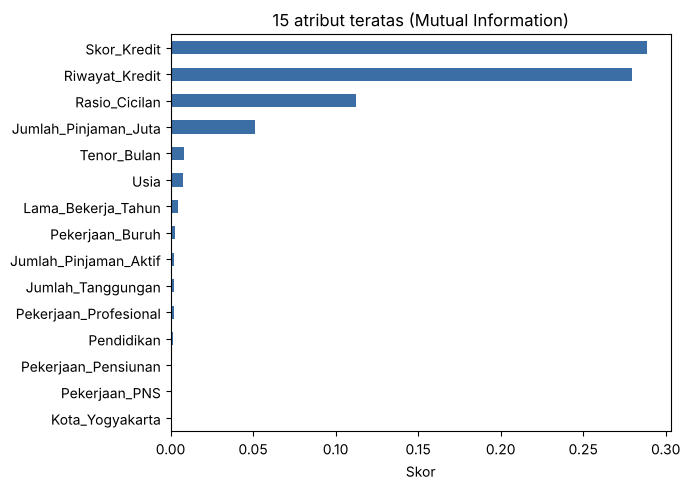

In [15]:
diskret = ~X.columns.isin(kolom_kontinu)          # True untuk atribut non-kontinu
mi = pd.Series(mutual_info_classif(X, y, discrete_features=diskret, random_state=42),
               index=X.columns).sort_values(ascending=False)

mi.head(15)[::-1].plot.barh(figsize=(7, 5), color="#3b6ea5")
plt.title("15 atribut teratas (Mutual Information)")
plt.xlabel("Skor")
plt.tight_layout()
plt.show()

Kita ambil **10 atribut teratas**, sisanya dibuang (reduksi dimensi). Atribut yang hampir tidak berpengaruh (misalnya Kota) hanya menambah noise.
(Di Orange: widget **Select Columns**.)

In [16]:
fitur_terpilih = mi.head(10).index.tolist()
X_red = X[fitur_terpilih]

print("Atribut sebelum:", X.shape[1], "-> sesudah:", X_red.shape[1])
print("Atribut terpilih:")
for f in fitur_terpilih:
    print(" -", f)

Atribut sebelum: 30 -> sesudah: 10
Atribut terpilih:
 - Skor_Kredit
 - Riwayat_Kredit
 - Rasio_Cicilan
 - Jumlah_Pinjaman_Juta
 - Tenor_Bulan
 - Usia
 - Lama_Bekerja_Tahun
 - Pekerjaan_Buruh
 - Jumlah_Pinjaman_Aktif
 - Jumlah_Tanggungan


## 2.6 Reduksi dimensi dengan PCA (pelengkap)
PCA merangkum atribut angka menjadi beberapa komponen. Grafik di bawah menunjukkan berapa persen informasi yang tertangkap bila kita pakai 1, 2, 3, dst. komponen.
(Di Orange: widget **PCA**.)

> Untuk Decision Tree kita tidak memakai hasil PCA, karena komponen PCA sulit dijelaskan. Tujuan Decision Tree adalah aturan yang mudah dibaca.

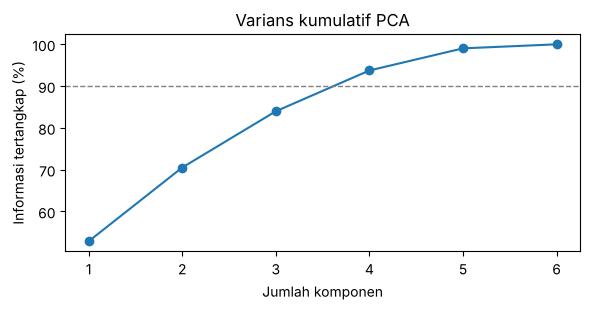

Komponen untuk >= 90% informasi: 4 dari 6


In [17]:
pca = PCA().fit(df_norm[kolom_kontinu])
kumulatif = pca.explained_variance_ratio_.cumsum() * 100

plt.figure(figsize=(6, 3.2))
plt.plot(range(1, len(kumulatif) + 1), kumulatif, marker="o")
plt.axhline(90, color="gray", ls="--", lw=1)
plt.xlabel("Jumlah komponen")
plt.ylabel("Informasi tertangkap (%)")
plt.title("Varians kumulatif PCA")
plt.tight_layout()
plt.show()

print("Komponen untuk >= 90% informasi:", int((kumulatif >= 90).argmax()) + 1, "dari", len(kumulatif))

## 2.7 Reduksi jumlah data (sampling), opsional
Berguna bila data sangat besar. Di sini hanya demonstrasi: mengambil 50% baris secara acak.
(Di Orange: widget **Data Sampler**.)

In [18]:
sampel = df.sample(frac=0.5, random_state=42)
print("Data asli:", len(df), "baris -> sampel:", len(sampel), "baris")
print("Proporsi kelas asli  :", df["Status_Persetujuan"].value_counts(normalize=True).round(2).to_dict())
print("Proporsi kelas sampel:", sampel["Status_Persetujuan"].value_counts(normalize=True).round(2).to_dict())

Data asli: 1200 baris -> sampel: 600 baris
Proporsi kelas asli  : {'Disetujui': 0.58, 'Ditolak': 0.42}
Proporsi kelas sampel: {'Disetujui': 0.56, 'Ditolak': 0.44}


# TAHAP 3: Klasifikasi Decision Tree

## 3.1 Membagi data latih dan data uji
80% data untuk **melatih** model, 20% untuk **menguji** model pada data yang belum pernah dilihat. `stratify=y` menjaga proporsi Disetujui/Ditolak tetap sama di kedua bagian.
(Di Orange: widget **Data Sampler** atau langsung *Test and Score*.)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_red, y, test_size=0.2, stratify=y, random_state=42)

print("Data latih:", X_train.shape[0], "baris")
print("Data uji  :", X_test.shape[0], "baris")

Data latih: 960 baris
Data uji  : 240 baris


## 3.2 Melatih dua pohon: C4.5 dan CART
Perbedaan utamanya ada pada **cara memilih pemisah**:

| | Kriteria | Di Python |
|---|---|---|
| **C4.5** | Information Gain (entropi) | `criterion="entropy"` |
| **CART** | Gini Index | `criterion="gini"` |

> Catatan jujur: scikit-learn hanya mengimplementasikan algoritma bergaya CART (pemisah biner). Opsi `entropy` memberi kriteria **mirip C4.5**, tetapi bukan C4.5 murni (tanpa gain ratio dan tanpa pemangkasan khas C4.5). Widget **Tree** di Orange juga demikian.

`max_depth=4` dan `min_samples_leaf=20` membatasi ukuran pohon supaya tidak terlalu rumit (mencegah *overfitting*).
(Di Orange: widget **Tree** dan **Test and Score**.)

In [20]:
model = {
    "C4.5 (entropy)": DecisionTreeClassifier(criterion="entropy", max_depth=4, min_samples_leaf=20, random_state=42),
    "CART (gini)":    DecisionTreeClassifier(criterion="gini",    max_depth=4, min_samples_leaf=20, random_state=42),
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

hasil = []
for nama, m in model.items():
    m.fit(X_train, y_train)
    hasil.append({
        "Model": nama,
        "Akurasi data uji": round(accuracy_score(y_test, m.predict(X_test)), 3),
        "Akurasi cross-validation 10-fold": round(cross_val_score(m, X_red, y, cv=cv).mean(), 3),
    })

pd.DataFrame(hasil)

,Model,Akurasi data uji,Akurasi cross-validation 10-fold
0,C4.5 (entropy),0.875,0.894
1,CART (gini),0.883,0.893


## 3.3 Melihat pohon keputusan
Setiap kotak adalah satu pertanyaan. Ikuti panah **kiri bila jawabannya Ya**, kanan bila Tidak, sampai ke daun yang berisi keputusan. Warna menunjukkan kelas dominan.
(Di Orange: widget **Tree Viewer**.)

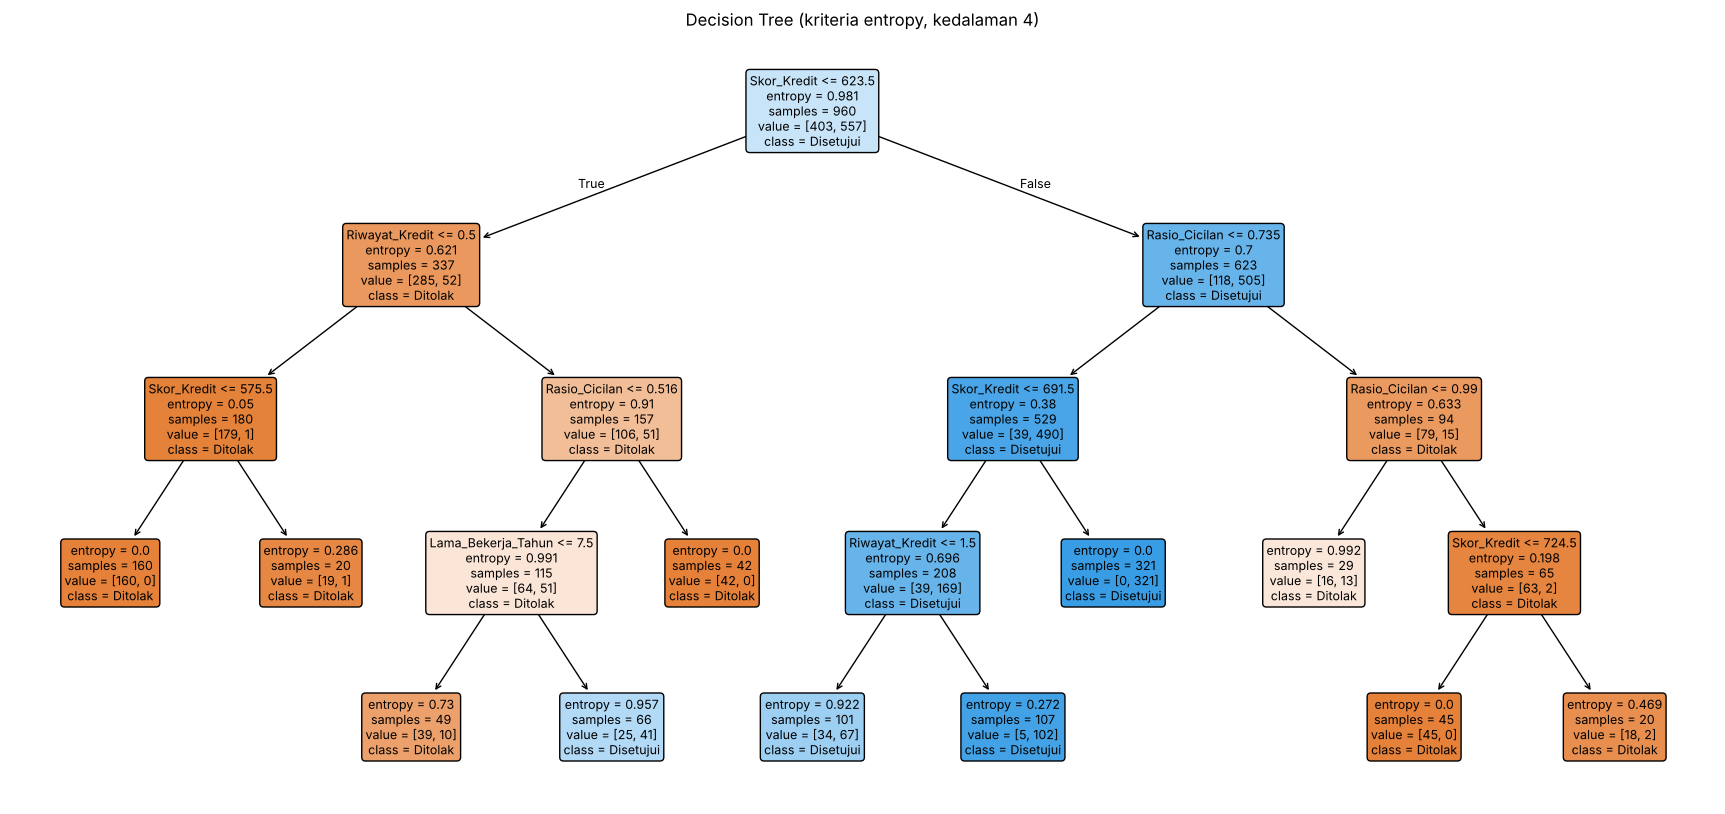

In [21]:
pohon = model["C4.5 (entropy)"]

plt.figure(figsize=(22, 10))
plot_tree(pohon, feature_names=X_red.columns, class_names=["Ditolak", "Disetujui"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (kriteria entropy, kedalaman 4)")
plt.show()

## 3.4 Aturan keputusan dalam bentuk teks
Pohon yang sama, ditulis sebagai aturan IF-THEN. `class: 1` = Disetujui, `class: 0` = Ditolak.

In [22]:
print(export_text(pohon, feature_names=list(X_red.columns), max_depth=3))

|--- Skor_Kredit <= 623.50
|   |--- Riwayat_Kredit <= 0.50
|   |   |--- Skor_Kredit <= 575.50
|   |   |   |--- class: 0
|   |   |--- Skor_Kredit >  575.50
|   |   |   |--- class: 0
|   |--- Riwayat_Kredit >  0.50
|   |   |--- Rasio_Cicilan <= 0.52
|   |   |   |--- Lama_Bekerja_Tahun <= 7.50
|   |   |   |   |--- class: 0
|   |   |   |--- Lama_Bekerja_Tahun >  7.50
|   |   |   |   |--- class: 1
|   |   |--- Rasio_Cicilan >  0.52
|   |   |   |--- class: 0
|--- Skor_Kredit >  623.50
|   |--- Rasio_Cicilan <= 0.73
|   |   |--- Skor_Kredit <= 691.50
|   |   |   |--- Riwayat_Kredit <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- Riwayat_Kredit >  1.50
|   |   |   |   |--- class: 1
|   |   |--- Skor_Kredit >  691.50
|   |   |   |--- class: 1
|   |--- Rasio_Cicilan >  0.73
|   |   |--- Rasio_Cicilan <= 0.99
|   |   |   |--- class: 0
|   |   |--- Rasio_Cicilan >  0.99
|   |   |   |--- Skor_Kredit <= 724.50
|   |   |   |   |--- class: 0
|   |   |   |--- Skor_Kredit >  724.50
|   |   |   | 

## 3.5 Evaluasi: seberapa baik pohonnya?
- **Precision**: dari yang diprediksi Disetujui, berapa yang benar.
- **Recall**: dari semua yang sebenarnya Disetujui, berapa yang berhasil ditemukan.
- **Confusion matrix**: tabel benar/salah tebak per kelas.

(Di Orange: widget **Confusion Matrix**.)

              precision    recall  f1-score   support

     Ditolak      0.890     0.802     0.844       101
   Disetujui      0.866     0.928     0.896       139

    accuracy                          0.875       240
   macro avg      0.878     0.865     0.870       240
weighted avg      0.876     0.875     0.874       240



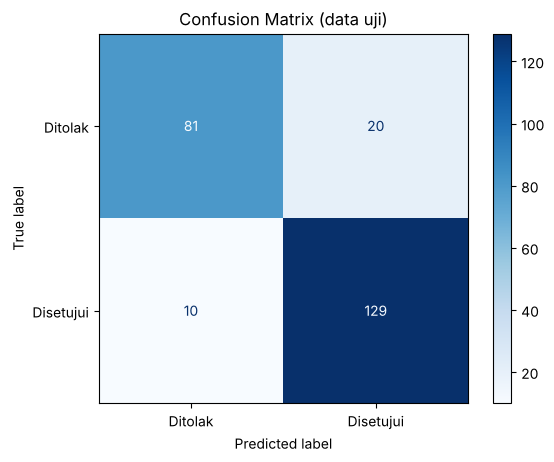

In [23]:
y_pred = pohon.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Ditolak", "Disetujui"], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Ditolak", "Disetujui"], cmap="Blues")
plt.title("Confusion Matrix (data uji)")
plt.show()

## 3.6 Atribut apa yang paling menentukan keputusan?

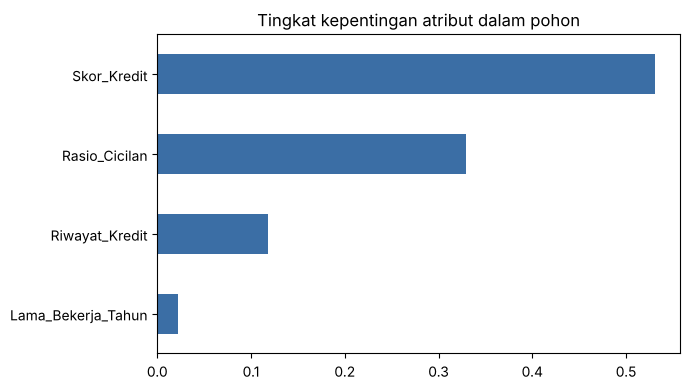

In [24]:
penting = pd.Series(pohon.feature_importances_, index=X_red.columns).sort_values()
penting[penting > 0].plot.barh(figsize=(7, 4), color="#3b6ea5")
plt.title("Tingkat kepentingan atribut dalam pohon")
plt.tight_layout()
plt.show()

## 3.7 Percobaan: seberapa dalam pohon sebaiknya?
Pohon yang terlalu dalam menghafal data latih (akurasi latih naik terus) tetapi akurasi uji tidak ikut naik atau malah turun. Itulah **overfitting**. Titik terbaik adalah kedalaman ketika akurasi uji paling tinggi sebelum mulai turun.

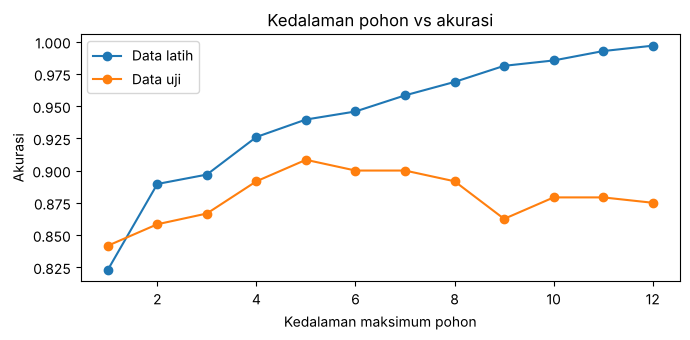

Kedalaman dengan akurasi uji tertinggi: 5 -> 0.908


In [25]:
kedalaman = range(1, 13)
acc_latih, acc_uji = [], []
for d in kedalaman:
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42).fit(X_train, y_train)
    acc_latih.append(m.score(X_train, y_train))
    acc_uji.append(m.score(X_test, y_test))

plt.figure(figsize=(7, 3.5))
plt.plot(kedalaman, acc_latih, marker="o", label="Data latih")
plt.plot(kedalaman, acc_uji, marker="o", label="Data uji")
plt.xlabel("Kedalaman maksimum pohon")
plt.ylabel("Akurasi")
plt.legend()
plt.title("Kedalaman pohon vs akurasi")
plt.tight_layout()
plt.show()

terbaik = kedalaman[int(np.argmax(acc_uji))]
print("Kedalaman dengan akurasi uji tertinggi:", terbaik, "->", round(max(acc_uji), 3))

# Ringkasan

1. **Integrasi**: dua tabel digabung lewat `ID_Nasabah` setelah duplikat dibuang.
2. **Cleansing**: label diseragamkan, outlier diubah menjadi kosong, missing value diisi median/modus.
3. **Transformasi**: atribut baru `Rasio_Cicilan`, normalisasi, diskretisasi, encoding.
4. **Reduksi**: dari semua atribut dipilih 10 teratas berdasarkan Mutual Information.
5. **Klasifikasi**: dua Decision Tree (entropy dan gini) dilatih dan dibandingkan dengan akurasi uji dan cross-validation.

Silakan ubah `max_depth`, `min_samples_leaf`, atau jumlah atribut terpilih (`mi.head(10)`), lalu jalankan ulang untuk melihat pengaruhnya.